# v101 Hertz point: BEM point contact against Hertz

**Question.** Does SlipPY's static BEM, driven through `slippy_bridge`, reproduce the Hertz
contact of a steel ball (12.7 mm) on a steel flat under 500 N (Johnson 1985, section 4.2(a),
Eqs (4.19)-(4.24), PDF p. 102-103), and from which grid?

**Reference.** r02 `hertz()` (SlipPY `hertz_full`, verified by José) of the same two bodies, at the
load the BEM carries. **Literature.** Johnson's printed constants `p0 = (3/2) p_m` and
`delta = a^2/R` evaluated on the BEM field alone.

**Criteria (README section 6, fixed before the run).** Spatial kernel, `b/h >= 16`, edge clear: C1
approach within 0.5 % (v_prerequisites row 1); C3 `p0` within `M^(-3/2)` and C4 `a`, `b` within `1/M`,
`M = 2b/h` (after Polonsky and Keer 1999, PDF p. 10; a proposed reading, see the README). RECORD: C2 load
found (C1 read the other way), C5 Polonsky-Keer `eps_p`, L1-L2 Johnson's constants, the frequency kernel
and the grid below `b/h = 16`. Interference control is the primary run (J-7), load control the
cross-check.

In [1]:
from IPython.display import Image, display
from axisforge.outputs._format import format_table

from studies.v100_dry_contact.v101_hertz_point import study

out = study.run()

## 1. Comparison with r02 (every grid, kernel and control)

   kernel       control    a/h  id  quantity          BEM          r02  rel err [%]  tol [%]  verdict
---------  ------------  -----  --  --------  -----------  -----------  -----------  -------  -------
  spatial  interference   8.99  C1     delta  1.18485e-05  1.18499e-05      -0.0120    0.500   RECORD
  spatial  interference   8.99  C2      load       500.09          500      +0.0179        -   RECORD
  spatial  interference   8.99  C3        p0  3.17635e+09  3.17321e+09      +0.0990    1.312   RECORD
  spatial  interference   8.99  C4         a  0.000275534  0.000274312      +0.4453    5.563   RECORD
  spatial  interference   8.99  C4         b  0.000275534  0.000274312      +0.4453    5.563   RECORD
  spatial  interference   8.99  C5     eps_p    0.0103789            0      +1.0379        -   RECORD
  spatial   normal_load   8.99  C1     delta  1.18471e-05  1.18485e-05      -0.0119    0.500   RECORD
  spatial   normal_load   8.99  C3        p0  3.17616e+09  3.17302e+09      +0.099

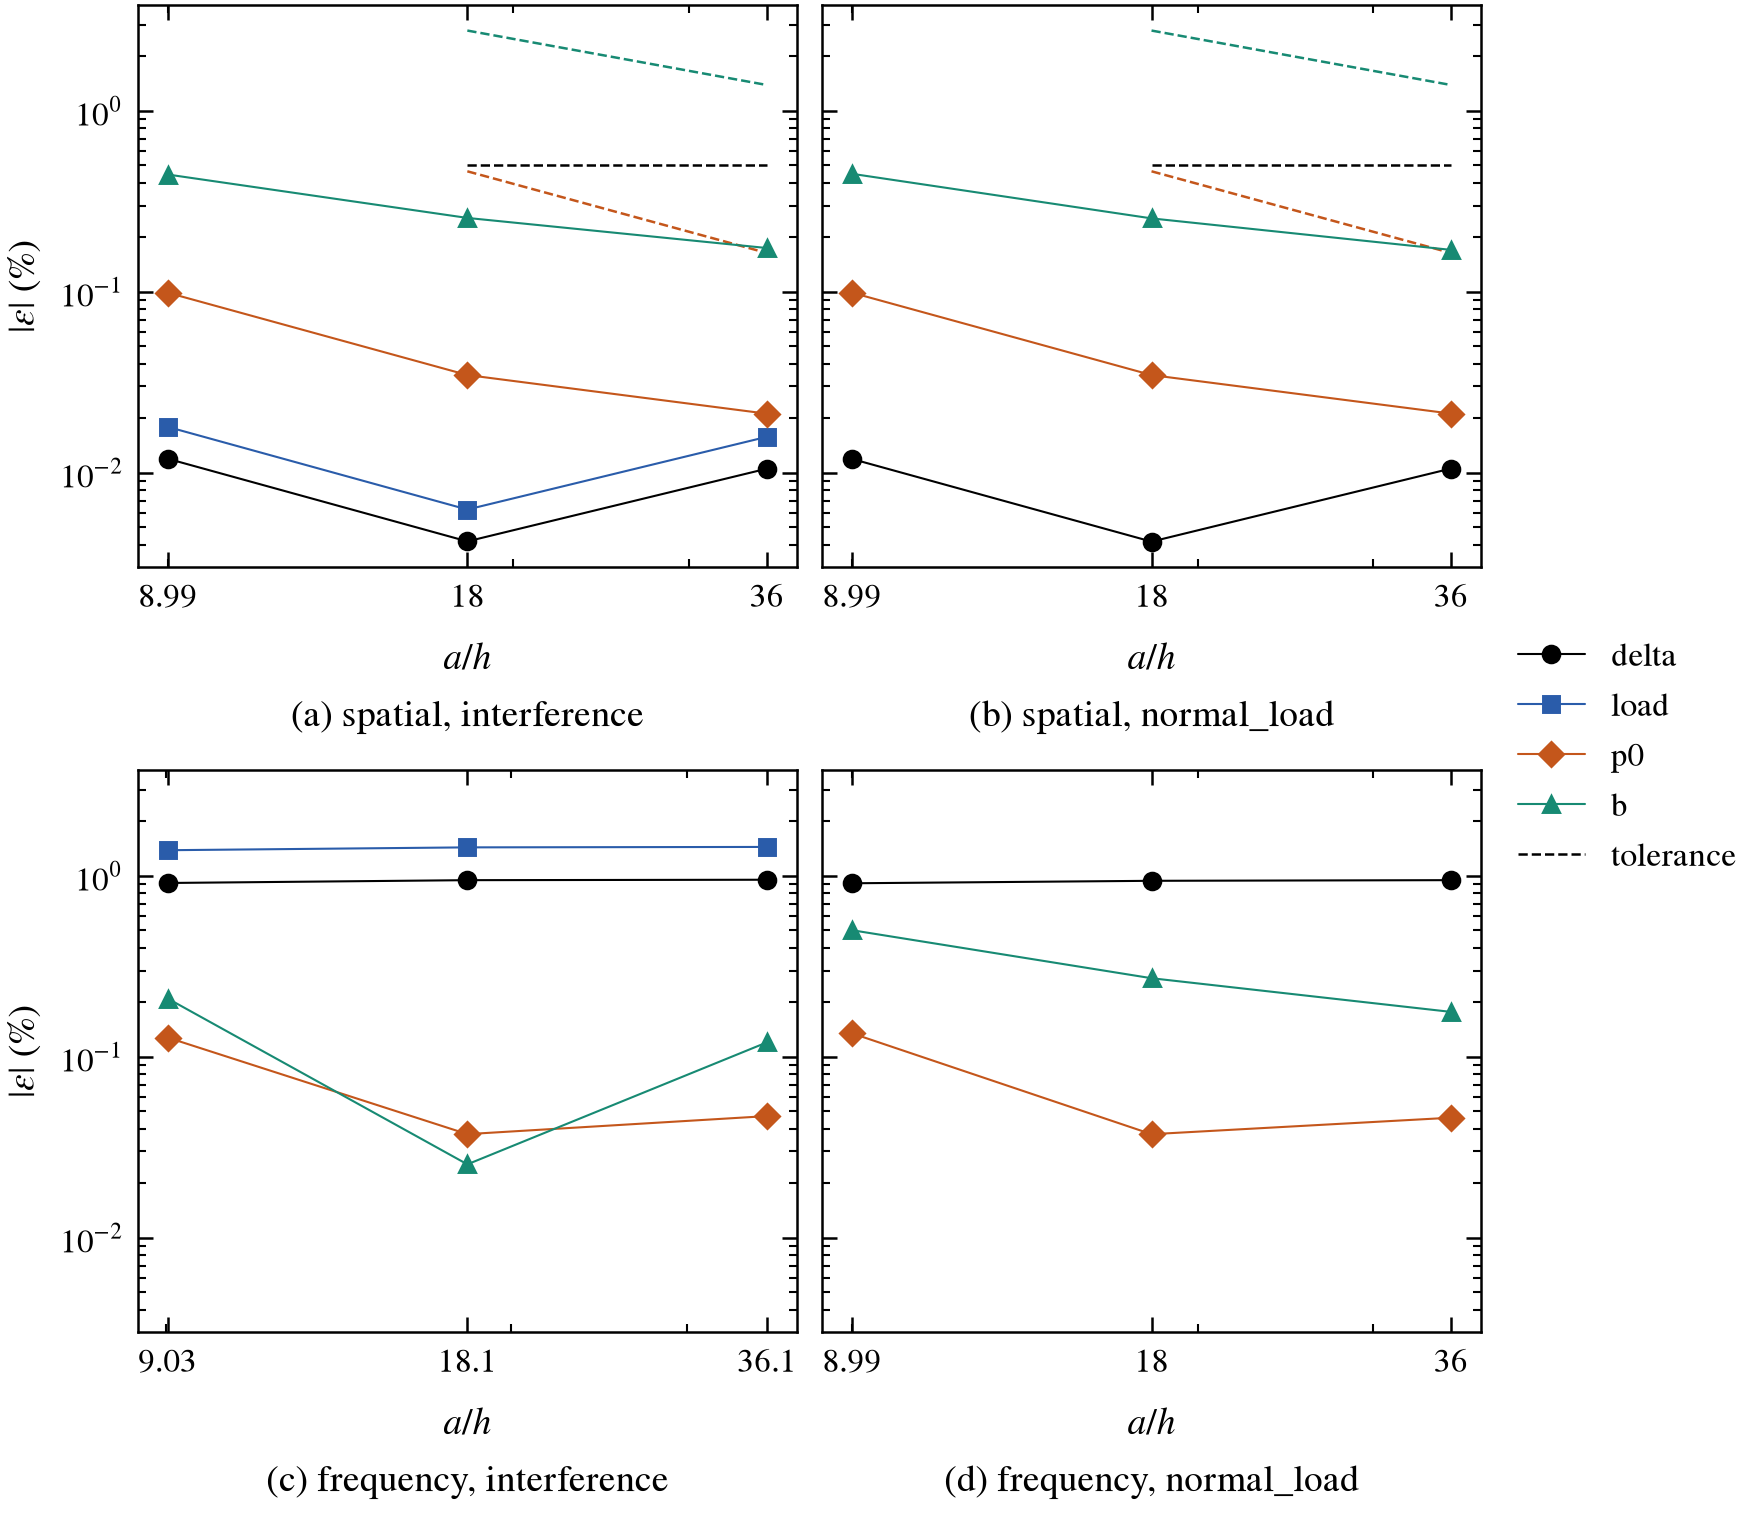

In [2]:
rows = [r for r in out["check"] if not r["id"].startswith("L")]
print(format_table((("kernel", "kernel", "s"), ("load_control", "control", "s"), ("a_over_h", "a/h", ".2f"),
                    ("id", "id", "s"), ("quantity", "quantity", "s"), ("measured", "BEM", ".6g"), ("reference", "r02", ".6g"),
                    ("rel_err", "rel err [%]", "+.4f", 100.0), ("tol", "tol [%]", ".3f", 100.0),
                    ("verdict", "verdict", "s")), rows))
display(Image(filename=str(out["figures"][0])))

## 2. Johnson's constants on the BEM field (RECORD: implied by C1-C4)

In [3]:
print(format_table((("id", "id", "s"), ("kernel", "kernel", "s"), ("load_control", "control", "s"),
                    ("b_over_h", "b/h", ".2f"), ("quantity", "quantity", "s"), ("measured", "BEM", ".5f"),
                    ("reference", "Johnson", "g"), ("rel_err", "rel err [%]", "+.4f", 100.0), ("source", "source", "s")),
                   [r for r in out["check"] if r["id"].startswith("L")]))

id     kernel       control    b/h       quantity      BEM  Johnson  rel err [%]                                         source
--  ---------  ------------  -----  -------------  -------  -------  -----------  ---------------------------------------------
L1    spatial  interference   8.99         p0/p_m  1.51489      1.5      +0.9924  Johnson1985 text after Eq. (4.21), PDF p. 103
L2    spatial  interference   8.99  delta R/(a b)  0.99103        1      -0.8965             Johnson1985 Eq. (4.23), PDF p. 103
L1    spatial   normal_load   8.99         p0/p_m  1.51501      1.5      +1.0007  Johnson1985 text after Eq. (4.21), PDF p. 103
L2    spatial   normal_load   8.99  delta R/(a b)  0.99095        1      -0.9046             Johnson1985 Eq. (4.23), PDF p. 103
L1    spatial  interference  17.98         p0/p_m  1.50822      1.5      +0.5481  Johnson1985 text after Eq. (4.21), PDF p. 103
L2    spatial  interference  17.98  delta R/(a b)  0.99494        1      -0.5064             Johnson1985

## 3. Pressure along the two axes (spatial kernel, `a/h` asked 16, got 17.98, interference control)

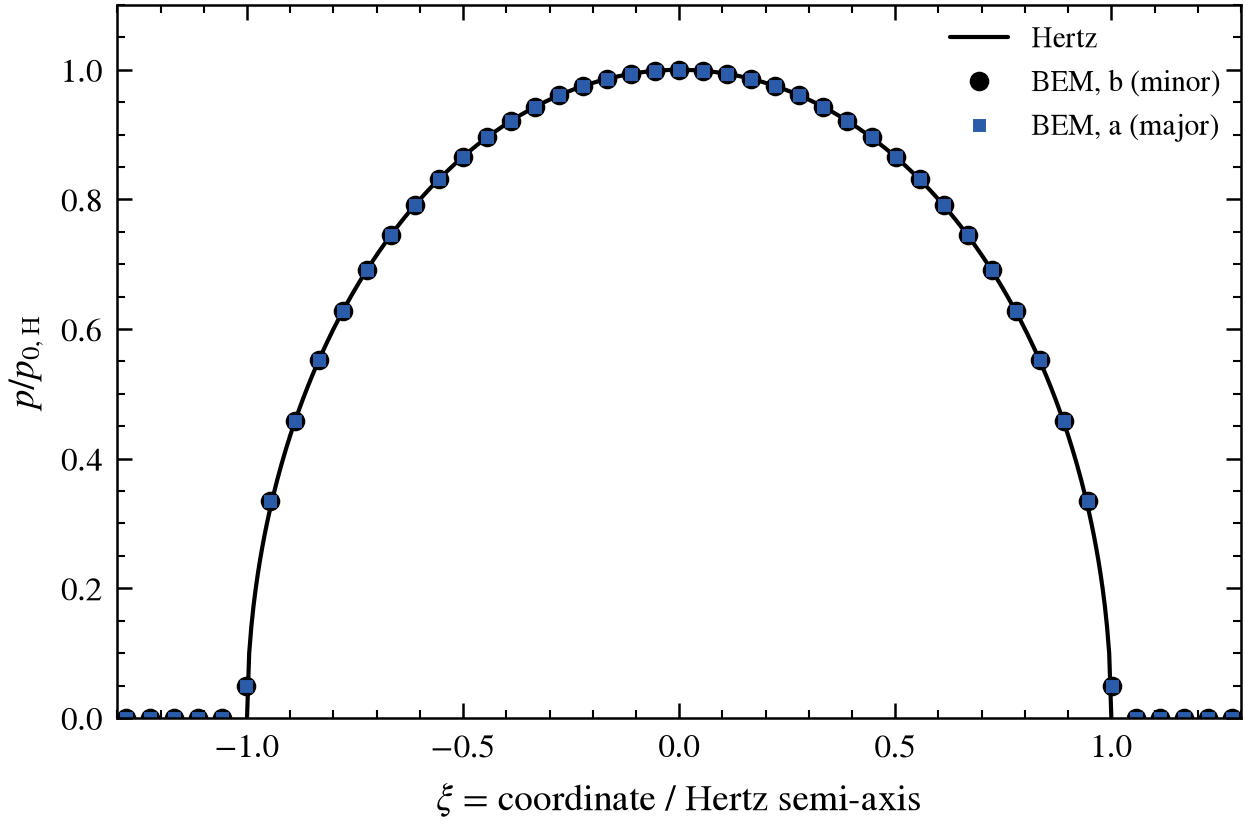

In [4]:
display(Image(filename=str(out["figures"][1])))

## 4. Verdict

In [5]:
judged = [r for r in out["check"] if r["verdict"] != "RECORD"]
misses = [r for r in judged if r["verdict"] == "MISS"]
print(f"judged {len(judged)}, PASS {len(judged) - len(misses)}, MISS {len(misses)}")
worst = max((r for r in out["check"] if r["verdict"] == "PASS"), key=lambda r: abs(r["rel_err"]) / r["tol"])
print(f"largest error / tolerance among the judged: {worst['quantity']} {100 * worst['rel_err']:+.4f} % "
      f"(tol {100 * worst['tol']:.3f} %) at a/h {worst['a_over_h']:.2f}")

judged 16, PASS 16, MISS 0
largest error / tolerance among the judged: p0 +0.0212 % (tol 0.164 %) at a/h 35.95
